# Tutorial 3: Visualizing the Norman Traffic Data
### MIS Data Analytics Case Competition — City of Norman

A good chart answers **one question** at a glance. In this tutorial you will build, step by step:

| Part | Chart | Question it answers |
|---|---|---|
| 2 | **Bar chart** | Which segments / days have the most crashes? |
| 3 | **Pie & donut chart** | What share of crashes does each cause make up? |
| 4 | **Line chart** | How do crashes change over time? |
| 5 | **Histogram & box plot** | How are V/C ratios spread out? |
| 6 | **Scatter plot** | Which segments are both congested *and* crash-prone? |
| 7 | **Heat map (table)** | When during the week do crashes happen? |
| 8 | **Dashboard** | Several answers on one page |
| 9 | **Interactive charts** (plotly) | Hover to see details |
| 10 | **Maps** — ward map, choropleth, interactive map with heat map | Where are the problems? |

Tools: `seaborn` for most charts, `matplotlib` for pies and dashboards, `plotly` for interactive charts, and
`geopandas` + `folium` for maps. All of them come installed in Colab.

---
## Part 0 — Setup and data

Files needed in your group's Drive folder:
* `Traffic_Project_OU_FALL_PROJECT.xlsx` (collisions) and `Code_Book.xlsx`
* `Council_Wards_4934068591990916100.geojson` (ward map)
* `segment_summary.csv` — one row per road segment with its volume, lanes, V/C, collisions, ward and position.
  It comes from the full project notebook (provided by your instructor).

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATA_FOLDER = '/content/drive/MyDrive/Colab Notebooks/MIS3213/Norman_Traffic_Analysis/data/'      # <-- change to your folder

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style='whitegrid')

### Load the crashes and prepare date columns
We drop crashes without coordinates (`-361`) only for the maps later; for the time charts every crash counts.
The `.dt` accessor pulls parts out of a date: year, month, weekday name, hour.

In [ ]:
crashes = pd.read_excel(DATA_FOLDER + 'Traffic_Project_OU_FALL_PROJECT.xlsx', sheet_name='Base_Data')

crashes['date'] = pd.to_datetime(crashes['AccidentDatetime'])
crashes['year'] = crashes['date'].dt.year
crashes['month'] = crashes['date'].dt.to_period('M').dt.to_timestamp()     # first day of the month
crashes['weekday'] = crashes['date'].dt.day_name()
crashes['hour'] = crashes['date'].dt.hour

print('Crashes:', len(crashes))
print('First:', crashes['date'].min().date(), ' Last:', crashes['date'].max().date())

Crashes: 23595
First: 2016-01-01  Last: 2026-08-11


In [ ]:
crashes.head()

,Year,AccidentNumber,AccidentDatetime,From_At,Direction,Distance,HouseNumber,StreetPrefix,StreetName,StreetType,...,XStreetType,XStreetSuffix,Lat,Lon,CauseCode,date,year,month,weekday,hour
0,2016,2016-00000027,2016-01-01 01:29:00,At,NaN,NaN,NaN,E,COMANCHE,ST,...,AVE,NaN,35.221158,-97.439919,-67028.0,2016-01-01 01:29:00,2016,2016-01-01,Friday,1
1,2016,2016-00000192,2016-01-01 22:20:00,From,DirectionSouth,35.0,NaN,NaN,12TH,AVE,...,RD,NaN,35.247342,-97.423480,-67028.0,2016-01-01 22:20:00,2016,2016-01-01,Friday,22
2,2016,2016-00000267,2016-01-02 10:34:00,From,DirectionEast,100.0,NaN,W,ROBINSON,ST,...,AVE,NaN,35.232927,-97.449941,-67239.0,2016-01-02 10:34:00,2016,2016-01-01,Saturday,10
3,2016,2016-00000279,2016-01-02 11:38:00,At,NaN,NaN,NaN,W,ROBINSON,ST,...,DR,NaN,35.232920,-97.488371,-68519.0,2016-01-02 11:38:00,2016,2016-01-01,Saturday,11
4,2016,2016-00000309,2016-01-02 14:04:00,From,DirectionNorth,25.0,NaN,NaN,ALAMEDA,ST,...,AVE,SE,35.218387,-97.423604,-67239.0,2016-01-02 14:04:00,2016,2016-01-01,Saturday,14


⚠️ The data ends in **August 2026**, so 2026 is a **partial year**. When we compare years, we use 2016–2025 only.

### Decode the cause codes with the Code Book

In [ ]:
codebook = pd.read_excel(DATA_FOLDER + 'Code_Book.xlsx')
code_meaning = dict(zip(codebook['EntryID'], codebook['Description']))

crashes['CauseCode'] = pd.to_numeric(crashes['CauseCode'], errors='coerce')
crashes['cause'] = crashes['CauseCode'].map(code_meaning).fillna('Unknown')
crashes['cause'].value_counts().head(8)

,count
cause,
Inattention Other,2917
Improper Act Other Unkn,2463
From Stop Sign,1580
Other Distraction Inside,1572
Changed Lanes Unsafely,1207
Human Element,1145
Incident Report,1117
Private Drive,885


In [ ]:
code_meaning

{-79990: nan,
 -67001: 'Abnormal Traffic Control',
 -67028: 'Alcohol DUI/DWI',
 -67050: 'Animal in Roadway',
 -67079: 'Apparently Sleepy',
 -67110: 'At Intersection',
 -67112: 'At Sidewalk/Stopline',
 -67129: 'Avoiding Other Vehicle',
 -67130: 'Avoiding Pedestrian',
 -67178: 'Brakes',
 -67239: 'Changed Lanes Unsafely',
 -67314: 'County Road at Through Highway',
 -67368: 'Deer in Roadway',
 -67369: 'Defect in Roadway',
 -67395: 'Disregarded Warning Signal',
 -67396: 'Distracted by Passenger in Vehicle',
 -67397: 'Distraction from Outside the Vehicle',
 -67406: 'Domestic Animal in Roadway',
 -67416: "Driver's Ability (Aged)",
 -67424: 'Drug - DUI',
 -67476: 'Exceeding Legal Limit',
 -67478: 'Exhaust System',
 -67486: 'Fail to Yield Other',
 -67488: 'Failed to Secure Load',
 -67489: 'Failed to Signal',
 -67490: 'Failed to Stop Other',
 -67544: 'For Ice or Snow on Roadway',
 -67545: 'For Officer/Flagman',
 -67546: 'For Railroad Gates/Signal',
 -67547: 'For School Bus',
 -67548: 'For Stop S

### Load the segment summary and the ward map

In [ ]:
segments = pd.read_csv(DATA_FOLDER + 'segment_summary.csv')
segments.head()

,segment,road,direction,wards,main_ward,years_counted,volume,lanes,capacity,vc,collisions,combined_rank,mid_lat,mid_lon
0,12th Ave NE/SE: Main St / Alameda St – Robinso...,12TH E,North-South,"4, 6",4,"FY19, FY21, FY26",31629.0,4D,38000,0.832,599,1,35.22565,-97.42355
1,Robinson: 12th Ave NW / Berry Rd – Porter Ave ...,ROBINSON,East-West,"4, 8",4,FY21,33112.0,5,36000,0.920,569,2,35.23291,-97.45010
2,Robinson: 36th Ave NW/SW – 24th Ave NW/SW,ROBINSON,East-West,"2, 3, 8",2,"FY19, FY23, FY25",29585.0,4D,38000,0.779,547,3,35.23293,-97.48550
3,12th Ave NE/SE: Lindsey St – Main St / Alameda St,12TH E,North-South,"1, 4",1,"FY19, FY23, FY25, FY26",27247.0,4D,38000,0.717,579,4,35.21115,-97.42361
4,Classen: Imhoff Rd – Lindsey St,CLASSEN,North-South,"1, 7",1,FY26,29872.0,4D,38000,0.786,414,5,35.19665,-97.42651


In [ ]:
segments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 127 entries, 0 to 126
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   segment        127 non-null    object 
 1   road           127 non-null    object 
 2   direction      127 non-null    object 
 3   wards          127 non-null    object 
 4   main_ward      127 non-null    int64  
 5   years_counted  127 non-null    object 
 6   volume         127 non-null    float64
 7   lanes          127 non-null    object 
 8   capacity       127 non-null    int64  
 9   vc             127 non-null    float64
 10  collisions     127 non-null    int64  
 11  combined_rank  127 non-null    int64  
 12  mid_lat        127 non-null    float64
 13  mid_lon        127 non-null    float64
dtypes: float64(4), int64(4), object(6)
memory usage: 14.0+ KB


In [ ]:
import geopandas as gpd
wards = gpd.read_file(DATA_FOLDER + 'Council_Wards_4934068591990916100.geojson')[['WARDNO', 'DIST_NAME', 'geometry']]
wards

,WARDNO,DIST_NAME,geometry
0,1,Ward 1,"POLYGON ((-97.41169 35.21835, -97.41112 35.218..."
1,2,Ward 2,"POLYGON ((-97.45902 35.22791, -97.45903 35.227..."
2,3,Ward 3,"POLYGON ((-97.48481 35.19378, -97.48516 35.193..."
3,4,Ward 4,"POLYGON ((-97.43973 35.23285, -97.43898 35.232..."
4,5,Ward 5,"POLYGON ((-97.35303 35.16032, -97.35391 35.160..."
5,6,Ward 6,"POLYGON ((-97.41335 35.21836, -97.41385 35.218..."
6,7,Ward 7,"POLYGON ((-97.43291 35.20383, -97.43281 35.203..."
7,8,Ward 8,"POLYGON ((-97.48722 35.30171, -97.48705 35.301..."


---
## Part 1 — Which chart should I use?

| I want to show... | Use |
|---|---|
| compare amounts between categories | **bar chart** |
| parts of a whole (few categories) | **pie / donut** |
| change over time | **line chart** |
| how values are spread | **histogram**, **box plot** |
| relationship between two numbers | **scatter plot** |
| a value for every combination of two categories | **heat map** |
| where things happen | **map** |

**Every chart needs:** a title that says what it shows, labeled axes with units, and readable category names.

---
## Part 2 — Bar charts

### 2.1 Count of crashes by weekday — `sns.countplot`
`countplot` counts rows for you. We fix the `order` so the days are in calendar order, not alphabetical.

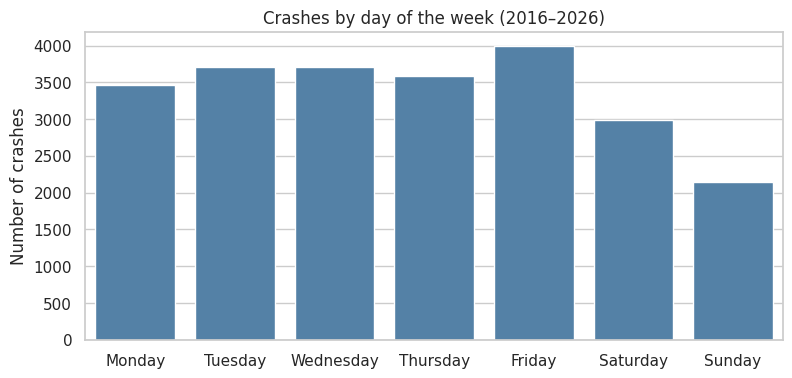

In [ ]:
DAYS = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

plt.figure(figsize=(9, 4))
sns.countplot(data=crashes, x='weekday', order=DAYS, color='steelblue')
plt.title('Crashes by day of the week (2016–2026)')
plt.xlabel('')
plt.ylabel('Number of crashes')
plt.show()

### 2.2 Top 10 segments by collisions — horizontal `sns.barplot`
Long category names (segment names) are easier to read on a **horizontal** bar chart: put the names on `y`.

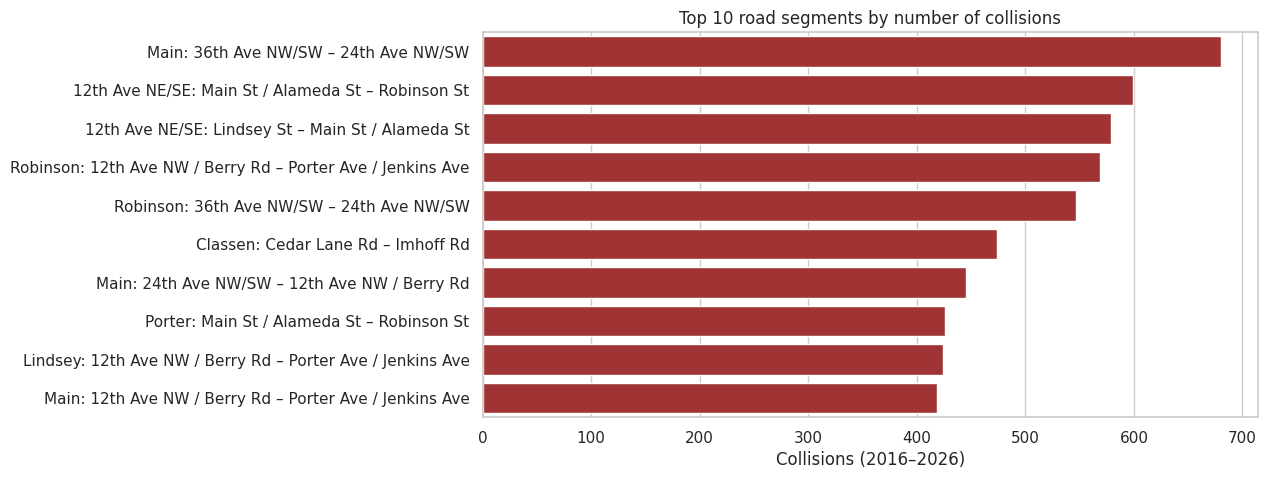

In [ ]:
top10 = segments.sort_values('collisions', ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=top10, x='collisions', y='segment', color='firebrick')
plt.title('Top 10 road segments by number of collisions')
plt.xlabel('Collisions (2016–2026)')
plt.ylabel('')
plt.show()

**Add the numbers to the bars** with `bar_label` — readers like exact values:

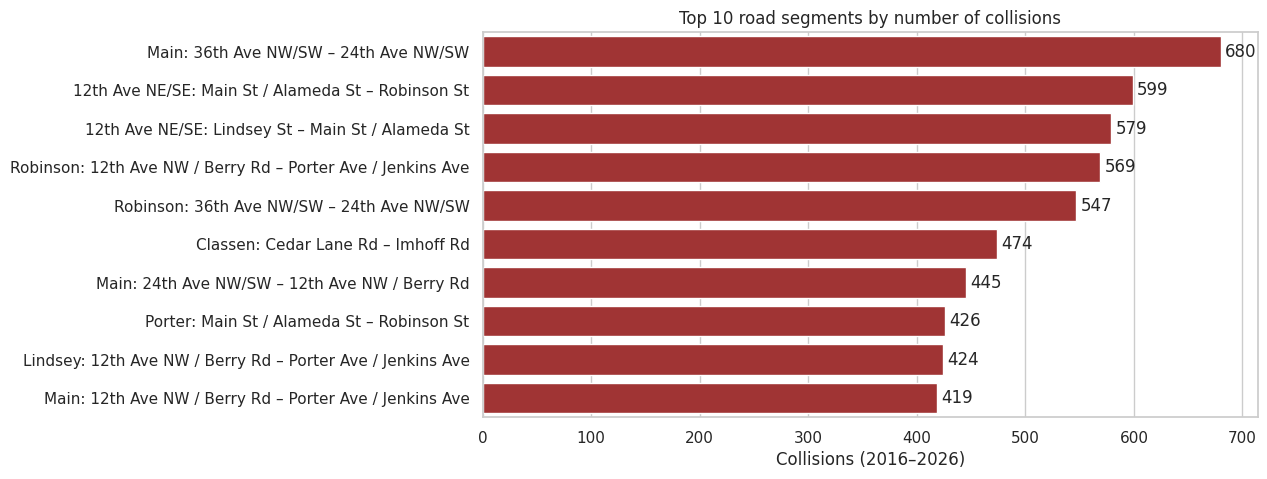

In [ ]:
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=top10, x='collisions', y='segment', color='firebrick')
ax.bar_label(ax.containers[0], padding=3)
plt.title('Top 10 road segments by number of collisions')
plt.xlabel('Collisions (2016–2026)')
plt.ylabel('')
plt.show()

### 2.3 Grouped bar chart — `hue`
`hue` splits each bar by a second category. Here: the **average V/C** in each ward, split by road direction.

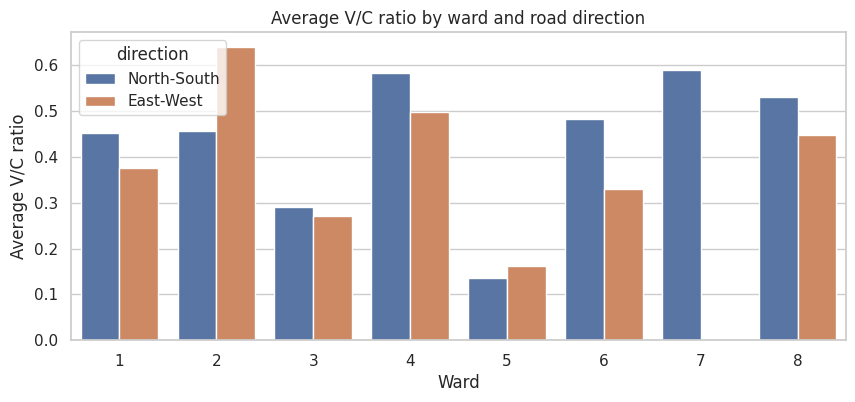

In [ ]:
plt.figure(figsize=(10, 4))
sns.barplot(data=segments, x='main_ward', y='vc', hue='direction', errorbar=None)
plt.title('Average V/C ratio by ward and road direction')
plt.xlabel('Ward')
plt.ylabel('Average V/C ratio')
plt.show()

---
## Part 3 — Pie and donut charts

Pie charts show **parts of a whole**. They only work with a **few slices** (about 6 or fewer), so we keep the top 5
causes and put the rest into "Other". Seaborn has no pie chart, so we use `plt.pie`.

In [ ]:
cause_counts = crashes['cause'].value_counts()
top5 = cause_counts.head(5)
pie_data = pd.concat([top5, pd.Series({'Other': cause_counts.iloc[5:].sum()})])
pie_data

,0
Inattention Other,2917
Improper Act Other Unkn,2463
From Stop Sign,1580
Other Distraction Inside,1572
Changed Lanes Unsafely,1207
Other,13856


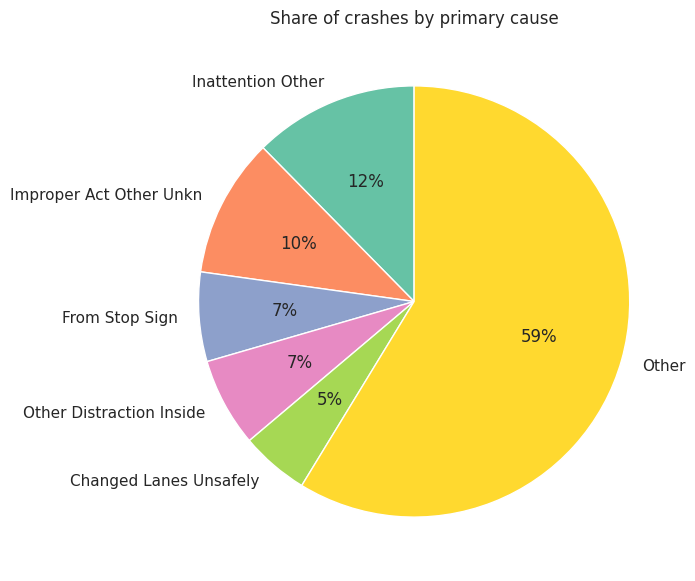

In [ ]:
plt.figure(figsize=(7, 7))
plt.pie(pie_data, labels=pie_data.index, autopct='%1.0f%%', startangle=90,
        colors=sns.color_palette('Set2', len(pie_data)))
plt.title('Share of crashes by primary cause')
plt.show()

A **donut** is a pie with a hole (`wedgeprops`). The hole is a good place for the total:

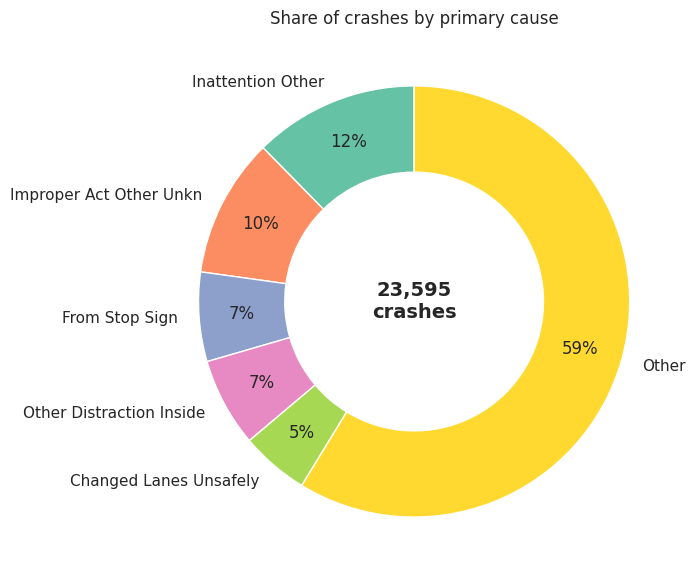

In [ ]:
plt.figure(figsize=(7, 7))
plt.pie(pie_data, labels=pie_data.index, autopct='%1.0f%%', startangle=90, pctdistance=0.8,
        colors=sns.color_palette('Set2', len(pie_data)), wedgeprops={'width': 0.4})
plt.text(0, 0, format(len(crashes), ',') + '\ncrashes', ha='center', va='center', fontsize=14, weight='bold')
plt.title('Share of crashes by primary cause')
plt.show()

Look at the result: **"Other" is 59%** — the causes are spread over dozens of codes, so the top 5 cover less than
half. That is a sign a pie is the wrong chart here. When you need more than about 6 categories, or one slice
swallows the rest, use a **bar chart** — comparing bar lengths is easier than comparing slice angles:

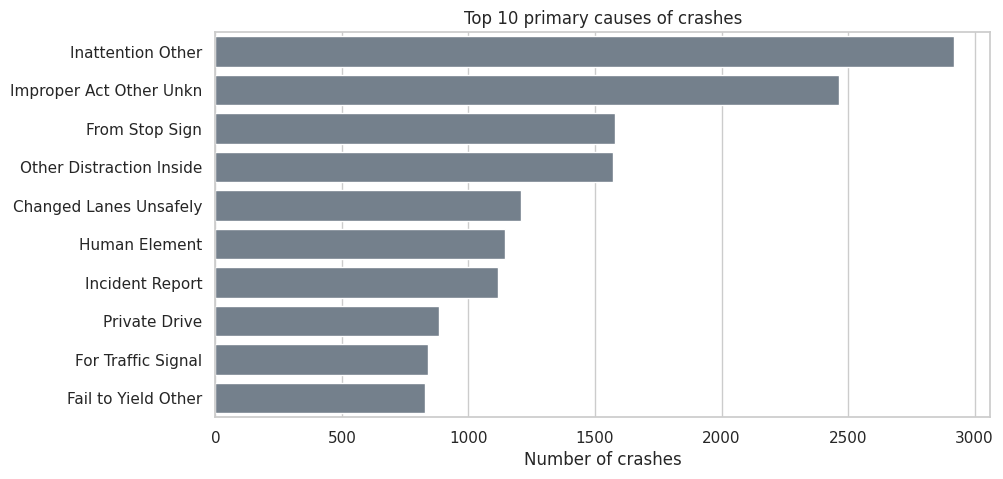

In [ ]:
plt.figure(figsize=(10, 5))
top10_causes = cause_counts.head(10).reset_index()
top10_causes.columns = ['cause', 'crashes']
sns.barplot(data=top10_causes, x='crashes', y='cause', color='slategray')
plt.title('Top 10 primary causes of crashes')
plt.xlabel('Number of crashes')
plt.ylabel('')
plt.show()

---
## Part 4 — Line charts

### 4.1 Crashes per year
First count crashes per year with `groupby(...).size()`, then plot. We leave out the partial year 2026.

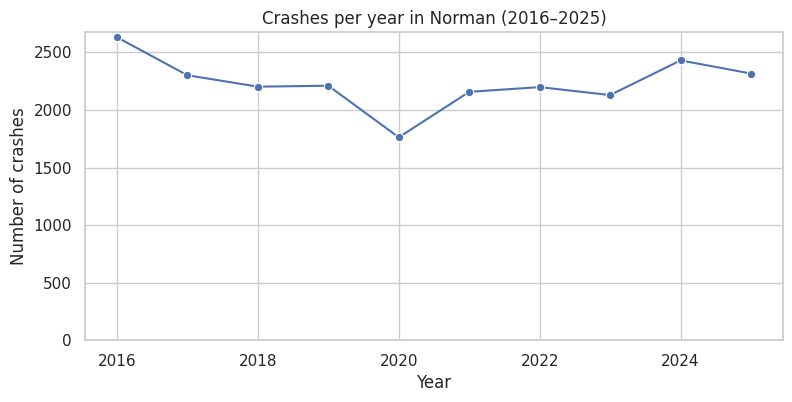

In [ ]:
per_year = crashes[crashes['year'] <= 2025].groupby('year').size().reset_index(name='crashes')

plt.figure(figsize=(9, 4))
sns.lineplot(data=per_year, x='year', y='crashes', marker='o')
plt.title('Crashes per year in Norman (2016–2025)')
plt.xlabel('Year')
plt.ylabel('Number of crashes')
plt.ylim(0)                          # start the y axis at 0 so changes are not exaggerated
plt.show()

### 4.2 Monthly crashes with a 12-month average
Monthly numbers jump around. A **rolling average** (`rolling(12).mean()`) smooths them to show the trend.
Notice the drop in spring 2020 (COVID-19 stay-at-home orders).

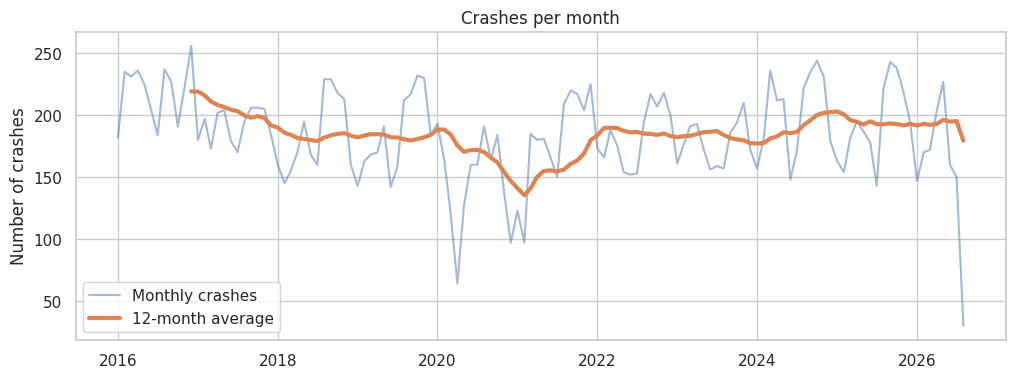

In [ ]:
per_month = crashes.groupby('month').size().reset_index(name='crashes')
per_month['12-month average'] = per_month['crashes'].rolling(12).mean()

plt.figure(figsize=(12, 4))
sns.lineplot(data=per_month, x='month', y='crashes', label='Monthly crashes', alpha=0.5)
sns.lineplot(data=per_month, x='month', y='12-month average', label='12-month average', linewidth=3)
plt.title('Crashes per month')
plt.xlabel('')
plt.ylabel('Number of crashes')
plt.show()

### 4.3 Several lines — one per road (`hue`)

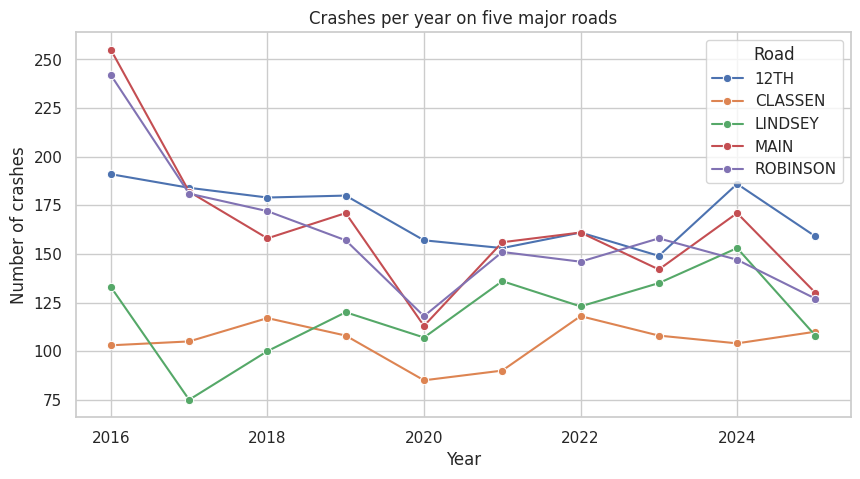

In [ ]:
main_roads = ['ROBINSON', 'MAIN', '12TH', 'LINDSEY', 'CLASSEN']
road_years = crashes[crashes['StreetName'].isin(main_roads) & (crashes['year'] <= 2025)]
road_per_year = road_years.groupby(['year', 'StreetName']).size().reset_index(name='crashes')

plt.figure(figsize=(10, 5))
sns.lineplot(data=road_per_year, x='year', y='crashes', hue='StreetName', marker='o')
plt.title('Crashes per year on five major roads')
plt.xlabel('Year')
plt.ylabel('Number of crashes')
plt.legend(title='Road')
plt.show()

---
## Part 5 — Histograms and box plots

### 5.1 Histogram — how are V/C ratios spread?

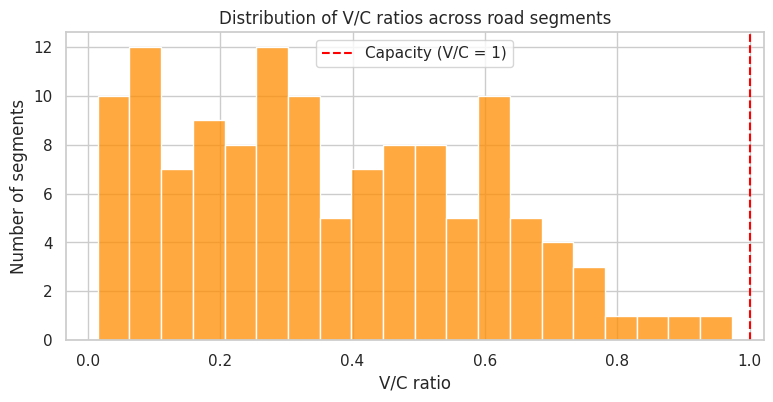

In [ ]:
plt.figure(figsize=(9, 4))
sns.histplot(data=segments, x='vc', bins=20, color='darkorange')
plt.axvline(1.0, color='red', linestyle='--', label='Capacity (V/C = 1)')
plt.title('Distribution of V/C ratios across road segments')
plt.xlabel('V/C ratio')
plt.ylabel('Number of segments')
plt.legend()
plt.show()

### 5.2 Box plot — compare groups
A box plot shows the **median** (middle line), the middle 50% (the box) and outliers (dots). Here: V/C by lane type.

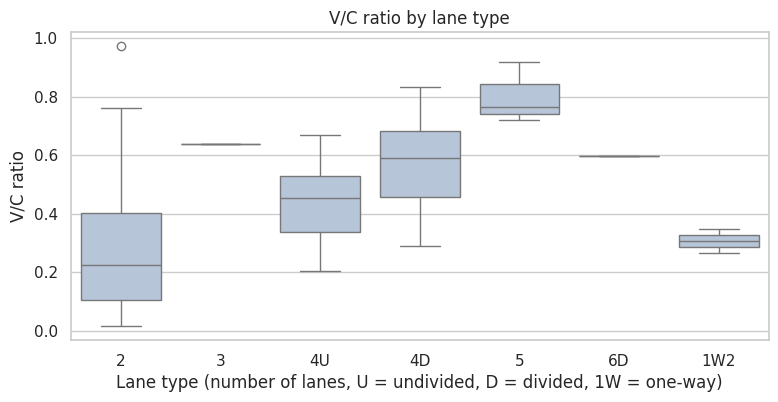

In [ ]:
plt.figure(figsize=(9, 4))
sns.boxplot(data=segments, x='lanes', y='vc', order=['2', '3', '4U', '4D', '5', '6D', '1W2'], color='lightsteelblue')
plt.title('V/C ratio by lane type')
plt.xlabel('Lane type (number of lanes, U = undivided, D = divided, 1W = one-way)')
plt.ylabel('V/C ratio')
plt.show()

---
## Part 6 — Scatter plot: congestion vs safety

Each dot is a segment: **V/C** on the x-axis, **collisions** on the y-axis. Dots in the **top-right** are both
congested and crash-prone — exactly what Q1 (the combined ranking) looks for. We draw lines at the **medians** to
split the chart into four quadrants, and label the top 5 segments.

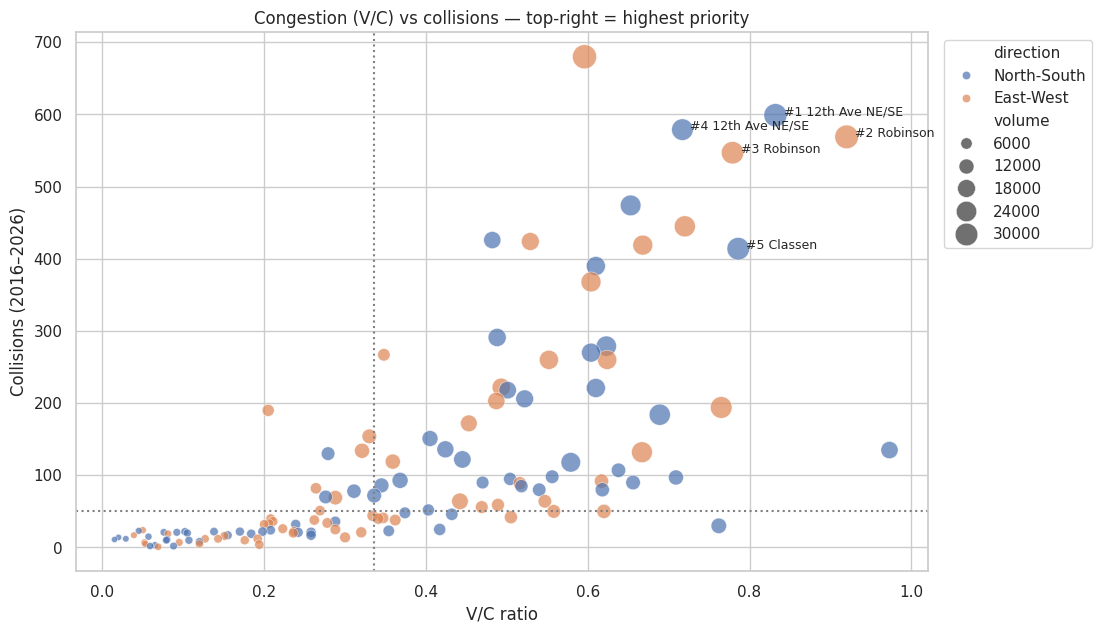

In [ ]:
plt.figure(figsize=(11, 7))
sns.scatterplot(data=segments, x='vc', y='collisions', hue='direction', size='volume', sizes=(20, 300), alpha=0.7)
plt.axvline(segments['vc'].median(), color='grey', linestyle=':')
plt.axhline(segments['collisions'].median(), color='grey', linestyle=':')

for i, row in segments.sort_values('combined_rank').head(5).iterrows():
    plt.text(row['vc'] + 0.01, row['collisions'], '#' + str(int(row['combined_rank'])) + ' ' + row['segment'].split(':')[0],
             fontsize=9)

plt.title('Congestion (V/C) vs collisions — top-right = highest priority')
plt.xlabel('V/C ratio')
plt.ylabel('Collisions (2016–2026)')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

---
## Part 7 — Heat map: when do crashes happen?

A heat map colors a **table**. First build the table with `pd.crosstab` (rows = weekday, columns = hour), then
`sns.heatmap` colors each cell by its count.

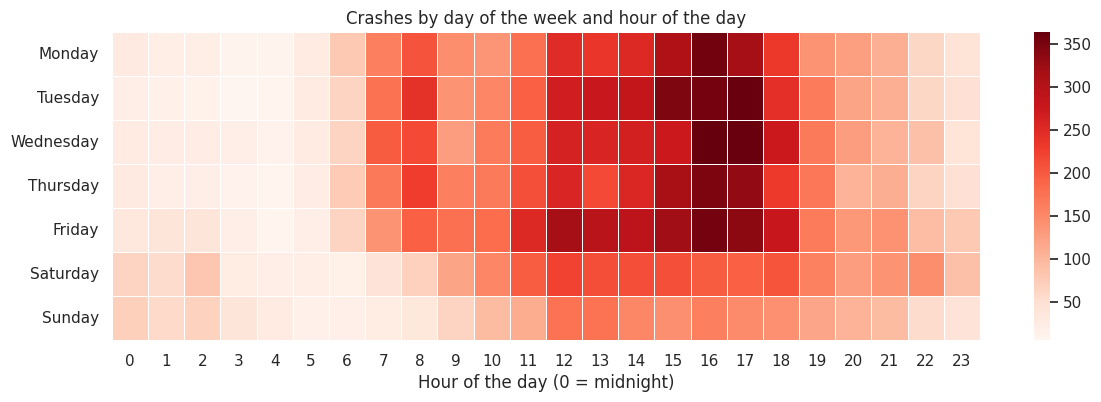

In [ ]:
table = pd.crosstab(crashes['weekday'], crashes['hour']).reindex(DAYS)

plt.figure(figsize=(14, 4))
sns.heatmap(table, cmap='Reds', linewidths=0.5)
plt.title('Crashes by day of the week and hour of the day')
plt.xlabel('Hour of the day (0 = midnight)')
plt.ylabel('')
plt.show()

Look for the dark cells: weekday **afternoon rush hour (3–6 pm)** is the worst time.

In [ ]:
table

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
weekday,,,,,,,,,,,,,,,,,,,,,
Monday,29,22,22,11,11,28,79,162,207,145,...,253,308,357,319,233,138,127,109,63,45
Tuesday,20,17,13,6,10,27,66,176,242,140,...,284,347,353,362,245,166,122,109,62,48
Wednesday,28,24,25,21,12,28,65,199,216,129,...,266,275,364,362,274,167,129,105,90,42
Thursday,29,20,20,12,9,23,76,169,229,162,...,256,315,348,333,232,170,105,110,66,48
Friday,34,40,40,20,10,20,67,139,194,179,...,292,321,353,337,279,166,136,141,93,79
Saturday,66,56,82,26,21,22,18,43,69,121,...,212,211,200,194,205,159,129,138,145,90
Sunday,71,59,68,40,27,16,19,26,37,66,...,152,144,160,148,142,120,104,95,56,43


---
## Part 8 — A dashboard

A **dashboard** puts several charts on one page so a decision-maker sees the full story at once. With
`plt.subplots(2, 2)` we get a 2 × 2 grid of axes; we pass each chart its `ax=`. The headline numbers (KPIs) go in
the title.

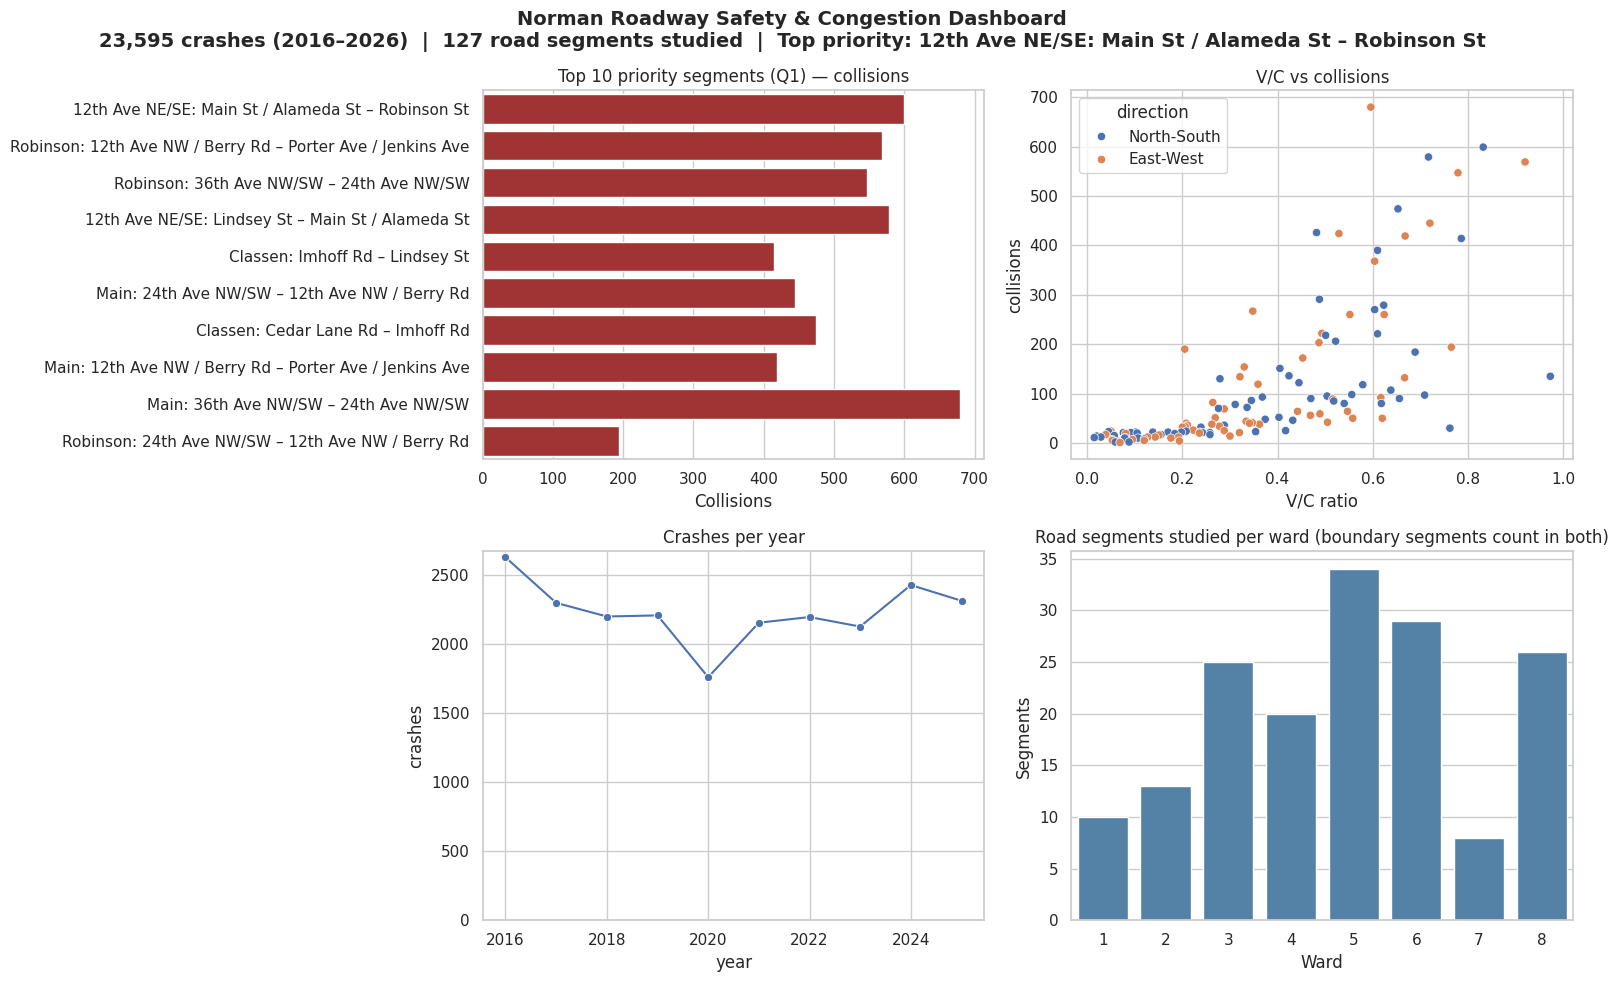

In [ ]:
total_crashes = len(crashes)
n_segments = len(segments)
worst = segments.sort_values('combined_rank').iloc[0]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Norman Roadway Safety & Congestion Dashboard\n'
             + format(total_crashes, ',') + ' crashes (2016–2026)  |  ' + str(n_segments) + ' road segments studied  |  '
             + 'Top priority: ' + worst['segment'], fontsize=14, weight='bold')

# top-left: top 10 combined priority
top_priority = segments.sort_values('combined_rank').head(10)
sns.barplot(data=top_priority, x='collisions', y='segment', color='firebrick', ax=axes[0, 0])
axes[0, 0].set_title('Top 10 priority segments (Q1) — collisions')
axes[0, 0].set_xlabel('Collisions')
axes[0, 0].set_ylabel('')

# top-right: scatter
sns.scatterplot(data=segments, x='vc', y='collisions', hue='direction', ax=axes[0, 1])
axes[0, 1].set_title('V/C vs collisions')
axes[0, 1].set_xlabel('V/C ratio')

# bottom-left: crashes per year
sns.lineplot(data=per_year, x='year', y='crashes', marker='o', ax=axes[1, 0])
axes[1, 0].set_title('Crashes per year')
axes[1, 0].set_ylim(0)

# bottom-right: segments per ward ("4, 6" -> one row for ward 4 and one for ward 6, so boundary segments count in both)
segments_per_ward = segments['wards'].astype(str).str.split(', ').explode().astype(int).value_counts().sort_index()
sns.barplot(x=segments_per_ward.index, y=segments_per_ward.values, color='steelblue', ax=axes[1, 1])
axes[1, 1].set_title('Road segments studied per ward (boundary segments count in both)')
axes[1, 1].set_xlabel('Ward')
axes[1, 1].set_ylabel('Segments')

plt.tight_layout()
plt.savefig(DATA_FOLDER + 'dashboard.png', dpi=150, bbox_inches='tight')     # save it for your report
plt.show()

---
## Part 9 — Interactive charts with plotly

`plotly.express` (imported as `px`) makes charts you can **hover, zoom and click**. The commands look a lot like
seaborn: give it the table, `x`, `y` and `color`.

In [ ]:
import plotly.express as px

fig = px.bar(top10.sort_values('collisions'), x='collisions', y='segment', orientation='h',
             title='Top 10 segments by collisions (hover over a bar)',
             hover_data=['volume', 'vc', 'wards'])
fig.show()

The scatter plot again — now **hover over any dot** to see which segment it is:

In [ ]:
fig = px.scatter(segments, x='vc', y='collisions', color='direction', size='volume',
                 hover_name='segment', hover_data=['wards', 'lanes', 'combined_rank'],
                 title='V/C vs collisions (interactive)')
fig.show()

In [ ]:
fig = px.line(per_month, x='month', y=['crashes', '12-month average'], title='Crashes per month (drag to zoom)')
fig.show()

Save an interactive chart as a web page with `fig.write_html(DATA_FOLDER + 'chart.html')`.

---
## Part 10 — Maps

### 10.1 Static ward map with segments
`wards.plot()` draws the ward polygons. On top, we draw each segment as a dot at its middle, **sized** by collisions
and **colored** by V/C.

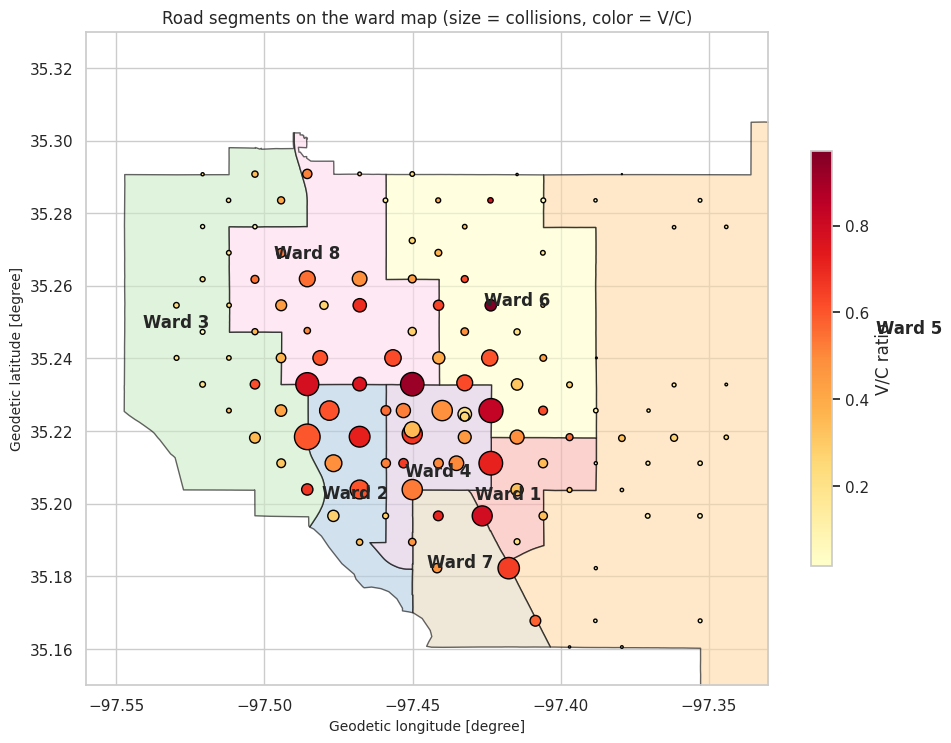

In [ ]:
fig, ax = plt.subplots(figsize=(11, 9))
wards.plot(ax=ax, column='WARDNO', categorical=True, cmap='Pastel1', edgecolor='black', alpha=0.6)
for i in range(len(wards)):
    center = wards['geometry'].iloc[i].representative_point()
    ax.text(center.x, center.y, 'Ward ' + str(wards['WARDNO'].iloc[i]), ha='center', weight='bold')

points = ax.scatter(segments['mid_lon'], segments['mid_lat'], s=segments['collisions'] / 2,
                    c=segments['vc'], cmap='YlOrRd', edgecolor='black')
plt.colorbar(points, ax=ax, shrink=0.6, label='V/C ratio')
ax.set_title('Road segments on the ward map (size = collisions, color = V/C)')
ax.set_xlim(-97.56, -97.33)
ax.set_ylim(35.15, 35.33)
plt.show()

### 10.2 Choropleth: crashes per ward
A **choropleth** colors each area by a number. We need the number of crashes **inside** each ward:
1. turn crash coordinates into map points (`gpd.points_from_xy`),
2. `gpd.sjoin` (spatial join) attaches the ward each point falls in,
3. count per ward and merge the counts back into the ward table.

In [ ]:
located = crashes[(crashes['Lat'] > 30) & (crashes['Lon'] < -90)].copy()          # drop the -361 "no location" rows
crash_points = gpd.GeoDataFrame(located, geometry=gpd.points_from_xy(located['Lon'], located['Lat']), crs='EPSG:4326')

crash_in_ward = gpd.sjoin(crash_points, wards, predicate='within')
crashes_per_ward = crash_in_ward.groupby('WARDNO').size().reset_index(name='crashes')

wards_counts = wards.merge(crashes_per_ward, on='WARDNO')
wards_counts[['WARDNO', 'DIST_NAME', 'crashes']]

,WARDNO,DIST_NAME,crashes
0,1,Ward 1,1533
1,2,Ward 2,3882
2,3,Ward 3,1927
3,4,Ward 4,4774
4,5,Ward 5,2232
5,6,Ward 6,2738
6,7,Ward 7,1386
7,8,Ward 8,2803


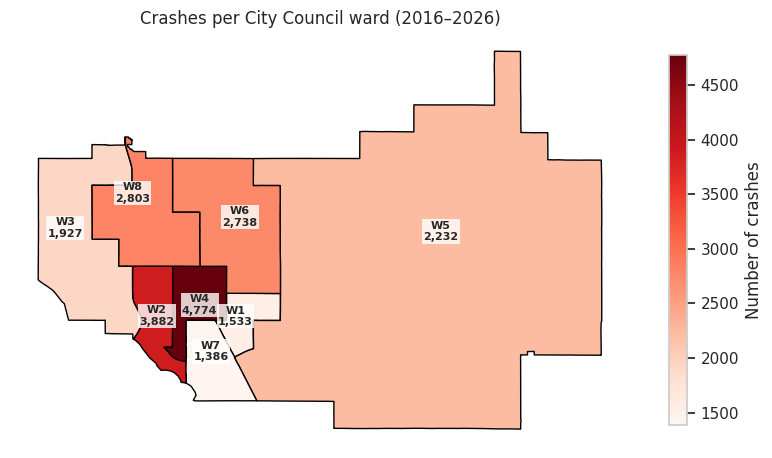

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))
wards_counts.plot(ax=ax, column='crashes', cmap='Reds', edgecolor='black', legend=True,
                  legend_kwds={'label': 'Number of crashes', 'shrink': 0.6})
for i in range(len(wards_counts)):
    center = wards_counts['geometry'].iloc[i].representative_point()
    ax.text(center.x, center.y, 'W' + str(wards_counts['WARDNO'].iloc[i]) + '\n' + format(wards_counts['crashes'].iloc[i], ','),
            ha='center', fontsize=8, weight='bold',
            bbox={'facecolor': 'white', 'alpha': 0.8, 'edgecolor': 'none', 'pad': 1})    # white box keeps text readable
ax.set_title('Crashes per City Council ward (2016–2026)')
ax.set_axis_off()
plt.show()

A big ward will naturally have more crashes. For a fair comparison you could divide by road miles or population —
a good discussion point for your presentation.

### 10.3 Interactive map with folium
`folium` makes a zoomable web map. We build it in **layers**:
1. a background map (we use Esri's free maps — OpenStreetMap's own tiles are blocked inside Colab),
2. the ward boundaries,
3. a **heat map** of crash locations,
4. a marker for each of the **top 20** priority segments (click it for details),
5. a layer switcher.

In [ ]:
import folium
from folium.plugins import HeatMap

ESRI_GRAY = 'https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}'
ESRI_SATELLITE = 'https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}'

m = folium.Map(location=[35.22, -97.44], zoom_start=12, tiles=None)
folium.TileLayer(ESRI_GRAY, attr='Tiles &copy; Esri', name='Gray map').add_to(m)
folium.TileLayer(ESRI_SATELLITE, attr='Tiles &copy; Esri, Maxar, Earthstar Geographics', name='Satellite').add_to(m)

# 2. ward boundaries
folium.GeoJson(wards, name='Ward boundaries',
               style_function=lambda feature: {'fillOpacity': 0.05, 'color': 'navy', 'weight': 2},
               tooltip=folium.GeoJsonTooltip(fields=['DIST_NAME'])).add_to(m)

# 3. heat map of crashes
heat_points = located[['Lat', 'Lon']].values.tolist()
HeatMap(heat_points, name='Crash heat map', radius=8, blur=10).add_to(m)

# 4. top 20 segments
top20 = segments.sort_values('combined_rank').head(20)
top20_layer = folium.FeatureGroup(name='Top 20 priority segments')
for i, row in top20.iterrows():
    popup = ('<b>#' + str(int(row['combined_rank'])) + ' ' + row['segment'] + '</b><br>'
             + 'Ward(s): ' + str(row['wards']) + '<br>'
             + 'Volume: ' + format(int(row['volume']), ',') + ' vehicles/day<br>'
             + 'V/C: ' + str(row['vc']) + '<br>'
             + 'Collisions: ' + str(row['collisions']))
    folium.CircleMarker(location=[row['mid_lat'], row['mid_lon']], radius=row['collisions'] / 40 + 4,
                        color='darkred', fill=True, fill_opacity=0.8,
                        popup=folium.Popup(popup, max_width=300),
                        tooltip='#' + str(int(row['combined_rank'])) + ' ' + row['segment']).add_to(top20_layer)
top20_layer.add_to(m)

# 5. layer switcher
folium.LayerControl(collapsed=False).add_to(m)
m

Try it: zoom in, click a red circle, switch to **Satellite**, and turn layers on and off.

### 10.4 Interactive choropleth
`folium.Choropleth` colors the wards by a number, like 10.2 but zoomable.

In [ ]:
m2 = folium.Map(location=[35.22, -97.38], zoom_start=11, tiles=None)
folium.TileLayer(ESRI_GRAY, attr='Tiles &copy; Esri', name='Gray map').add_to(m2)
folium.Choropleth(geo_data=wards_counts, data=crashes_per_ward, columns=['WARDNO', 'crashes'],
                  key_on='feature.properties.WARDNO', fill_color='Reds', fill_opacity=0.7,
                  legend_name='Crashes per ward (2016–2026)').add_to(m2)
folium.GeoJson(wards_counts, style_function=lambda feature: {'fillOpacity': 0, 'weight': 0},
               tooltip=folium.GeoJsonTooltip(fields=['DIST_NAME', 'crashes'], aliases=['Ward', 'Crashes'])).add_to(m2)
m2

---
## Part 11 — Save your charts and maps

| What | How |
|---|---|
| seaborn / matplotlib chart | `plt.savefig(DATA_FOLDER + 'name.png', dpi=150, bbox_inches='tight')` **before** `plt.show()` |
| plotly chart | `fig.write_html(DATA_FOLDER + 'name.html')` |
| folium map | `m.save(DATA_FOLDER + 'name.html')` |

In [ ]:
m.save(DATA_FOLDER + 'norman_interactive_map.html')
print('Saved the interactive map. Open it from Google Drive in any web browser.')

Saved the interactive map. Open it from Google Drive in any web browser.


---
## Summary — chart cheat sheet

| Chart | Code |
|---|---|
| Bar (counts) | `sns.countplot(data=df, x='col', order=[...])` |
| Bar (values) | `sns.barplot(data=df, x='value', y='name')` + `ax.bar_label(...)` |
| Grouped bar | `sns.barplot(..., hue='group')` |
| Pie / donut | `plt.pie(values, labels=..., autopct='%1.0f%%', wedgeprops={'width': 0.4})` |
| Line | `sns.lineplot(data=df, x='year', y='count', hue='group', marker='o')` |
| Rolling average | `df['avg'] = df['count'].rolling(12).mean()` |
| Histogram | `sns.histplot(data=df, x='col', bins=20)` |
| Box plot | `sns.boxplot(data=df, x='group', y='value')` |
| Scatter | `sns.scatterplot(data=df, x=..., y=..., hue=..., size=...)` |
| Heat map | `sns.heatmap(pd.crosstab(df['a'], df['b']))` |
| Dashboard | `fig, axes = plt.subplots(2, 2)` and `ax=axes[r, c]` |
| Interactive | `px.bar`, `px.scatter(hover_name=...)`, `px.line` |
| Map (static) | `gdf.plot(column='value', legend=True)` |
| Points in areas | `gpd.sjoin(points, areas, predicate='within')` |
| Map (interactive) | `folium.Map`, `HeatMap`, `CircleMarker`, `Choropleth`, `LayerControl` |

